# Avance 3. Construcción del Modelo Baseline
### Equipo 11 - Proyecto Integrador

Este avance tiene como objetivo establecer un modelo de referencia (baseline) para evaluar la viabilidad de clasificar automáticamente los segmentos de texto extraídos de las sesiones de arquitectura técnica en Google Cloud.

Dado que el objetivo final del proyecto es utilizar un enfoque agéntico con Modelos Fundacionales Multimodales (Gemini 2.5 Pro) para generar *Technical Design Documents* (TDD), este baseline de Machine Learning tradicional servirá para:
1. **Validar la señal de los datos:** Comprobar si las transcripciones (simuladas en esta muestra piloto) y sus metadatos contienen información discriminatoria suficiente para clasificar si un segmento corresponde a un *Requisito* (`requirement`), un *Próximo paso* (`next_steps`), una *Migración de base de datos* (`database_migration`), una *Discusión técnica* (`technical_discussion`) o una *Decisión de arquitectura* (`architecture_decision`).
2. **Justificar la IA Generativa:** Documentar matemáticamente las limitaciones de los modelos clásicos (como el sobreajuste debido a la escasez de datos) para defender la necesidad de enfoques Zero-Shot/Few-Shot con LLMs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, learning_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix

# 1. PREPARACIÓN DEL CONJUNTO DE DATOS
df_merged = pd.read_csv('datos_preprocesados_avance2.csv')
print(f"Datos cargados con {df_merged.shape[0]} filas y {df_merged.shape[1]} columnas.")
df_baseline = df_merged.copy()
df_baseline['text_clean'] = df_baseline['text_clean'].fillna('')

# 1.1 REVISIÓN DEL IDIOMA DE LOS TEXTOS
# Las transcripciones reales están en inglés. Los únicos textos en español son 27 filas de relleno
# ("Discusión técnica sobre el segmento N.") de las sesiones S01-S05, que no describen el contenido
# y por tanto no permiten aprender la etiqueta. Se excluyen y se mantiene stop_words='english'.
es_placeholder = df_baseline['text_clean'].str.startswith('Discusión técnica sobre el segmento')
print(f"Filas de relleno en español excluidas: {es_placeholder.sum()}")
df_baseline = df_baseline[~es_placeholder]

# 1.2 ELIMINACIÓN DE FRASES DUPLICADAS
# La misma frase aparece en varias sesiones (siempre con la misma etiqueta). Si una copia queda en
# entrenamiento y otra en prueba, el modelo "memoriza" la respuesta e infla la métrica.
n_antes = len(df_baseline)
df_baseline = df_baseline.drop_duplicates(subset='text_clean', keep='first').reset_index(drop=True)
print(f"Frases duplicadas eliminadas: {n_antes - len(df_baseline)} -> quedan {len(df_baseline)} segmentos únicos")
print(df_baseline['expected_category'].value_counts().to_string(), "\n")

# Variables predictoras (X)
# Usaremos TF-IDF (stop words en inglés, idioma de las transcripciones reales). Añadimos max_df=0.85 para controlar el efecto inflado de palabras de plantillas
tfidf = TfidfVectorizer(max_features=100, ngram_range=(1, 2), stop_words='english', max_df=0.85)
X_text = tfidf.fit_transform(df_baseline['text_clean']).toarray()
text_feature_names = [f"word_{w}" for w in tfidf.get_feature_names_out()]

# Seleccionamos características numéricas relevantes del EDA/Avance 2
num_features = ['segment_duration_sec', 'word_count', 'avg_word_length', 'num_speakers']
X_num = df_baseline[num_features].values

# Concatenamos texto estructurado + metadatos numéricos
X = np.hstack((X_text, X_num))
feature_names = text_feature_names + num_features

# Variable objetivo (y) y variable de agrupación (groups)
y = df_baseline['expected_category']
groups = df_baseline['session_id'] # Variable clave para evitar data leakage entre sesiones

# División en Entrenamiento y Prueba respetando la agrupación por sesión (Recomendación del profesor)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Dimensiones de Entrenamiento: X={X_train.shape}, y={y_train.shape}")
print(f"Dimensiones de Prueba: X={X_test.shape}, y={y_test.shape}")

Datos cargados con 139 filas y 20 columnas.
Filas de relleno en español excluidas: 27
Frases duplicadas eliminadas: 36 -> quedan 76 segmentos únicos
expected_category
requirement              26
next_steps               23
database_migration       13
technical_discussion      9
architecture_decision     5 

Dimensiones de Entrenamiento: X=(64, 104), y=(64,)
Dimensiones de Prueba: X=(12, 104), y=(12,)


## 3.1 Algoritmo y 3.4 Métrica de Evaluación

**Algoritmo Seleccionado:** `RandomForestClassifier`

Se seleccionó un Bosque Aleatorio (Random Forest) como modelo baseline considerando las características del problema y de los datos:

* **Tipo de problema:** clasificación supervisada multiclase (5 categorías) de segmentos de reunión.
* **Tipo de datos (mixtos):** combina datos **no estructurados** (texto de la transcripción, representado con vectores TF-IDF dispersos de 100 términos) con datos **estructurados** de distinta escala (`segment_duration_sec`, `word_count`, `avg_word_length`, `num_speakers`). Los árboles no requieren escalar ni normalizar las variables, por lo que ambos tipos se pueden combinar directamente.
* **Cantidad de datos:** tras la limpieza quedan **76 segmentos únicos y 104 características**, es decir, más variables que observaciones. En este escenario un modelo de un solo árbol sobreajustaría con facilidad; el ensamble de 100 árboles con *bagging* reduce la varianza, y se limita la profundidad (`max_depth=10`) para controlar la complejidad.
* **Clases desbalanceadas:** se usa `class_weight='balanced'` para que las clases minoritarias (`architecture_decision`, con solo 5 ejemplos) tengan peso en el entrenamiento.
* **Presencia de características relevantes:** no sabemos de antemano qué variables aportan; Random Forest selecciona internamente las más útiles en cada división, y es robusto ante características irrelevantes o correlacionadas (por ejemplo, unigramas y bigramas que se solapan).
* **Interpretabilidad:** al ser un ensamble de árboles, provee un método embebido nativo (`feature_importances_`) y es compatible con la importancia por permutación, lo que permite responder si el modelo se guía por la metadata del segmento o por el contenido técnico (sección 3.2).
* **Alternativas consideradas:** Naive Bayes, Regresión Logística y SVM lineal son baselines habituales para texto. En la sección 3.6 se comparan empíricamente: rinden ligeramente mejor que Random Forest, pero la diferencia queda dentro de la variabilidad entre particiones y ninguno alcanza la meta de negocio. Se mantiene Random Forest porque permite analizar en un mismo modelo el aporte de la metadata frente al contenido léxico, que es lo que este baseline busca validar.

**Métrica Seleccionada:** `F1-Score (Macro)`

Tras la limpieza, la distribución de la variable objetivo es desbalanceada:

| Categoría | Segmentos | % |
|---|---|---|
| `requirement` | 26 | 34% |
| `next_steps` | 23 | 30% |
| `database_migration` | 13 | 17% |
| `technical_discussion` | 9 | 12% |
| `architecture_decision` | 5 | 7% |

La clase mayoritaria es más de 5 veces más frecuente que la minoritaria. El *Accuracy* sería engañoso: un modelo que ignore `architecture_decision` y `technical_discussion` puede tener un accuracy alto y aun así omitir las secciones más críticas del documento.

El **F1-Macro** calcula el F1 de cada clase y los promedia con el mismo peso, de modo que fallar en una clase minoritaria penaliza la métrica tanto como fallar en una mayoritaria. Esto se alinea con el objetivo de negocio: en el *Technical Design Document* (TDD) cada categoría alimenta una sección distinta, y omitir una sola *Decisión de arquitectura* deja incompleto el documento tanto como omitir un *Requisito*. Además, el F1 equilibra precisión (no meter segmentos en la sección equivocada del TDD) y exhaustividad (no perder segmentos relevantes), ambas importantes porque un consultor revisa el borrador generado.

In [2]:
# 2. ENTRENAMIENTO DEL MODELO BASELINE

# Definimos un Dummy Classifier para obtener el desempeño mínimo por azar (regla heurística)
dummy_clf = DummyClassifier(strategy='stratified', random_state=42)
dummy_clf.fit(X_train, y_train)
y_pred_dummy = dummy_clf.predict(X_test)
f1_dummy = f1_score(y_test, y_pred_dummy, average='macro', zero_division=0)

# Entrenamos el Baseline (Random Forest)
rf_baseline = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced')
rf_baseline.fit(X_train, y_train)

# Predicciones
y_pred_train = rf_baseline.predict(X_train)
y_pred_test = rf_baseline.predict(X_test)

# Evaluación
f1_train = f1_score(y_train, y_pred_train, average='macro', zero_division=0)
f1_test = f1_score(y_test, y_pred_test, average='macro', zero_division=0)
accuracy_test = accuracy_score(y_test, y_pred_test)

print("--- Desempeño del Baseline ---")
print(f"Desempeño mínimo por azar (Dummy Classifier F1-Macro): {f1_dummy:.4f}")
print(f"Random Forest F1-Macro (Train): {f1_train:.4f}")
print(f"Random Forest F1-Macro (Test):  {f1_test:.4f}")
print(f"Random Forest Accuracy (Test):  {accuracy_test:.4f}\n")

print("Reporte de Clasificación (Conjunto de Prueba):")
print(classification_report(y_test, y_pred_test, zero_division=0))
# Con pocos segmentos únicos, una sola partición de prueba es frágil.
# Complementamos con validación cruzada agrupada por sesión (GroupKFold).
from sklearn.model_selection import GroupKFold, cross_validate
gkf = GroupKFold(n_splits=5)
cv_rf = cross_validate(rf_baseline, X, y, groups=groups, cv=gkf, scoring='f1_macro', return_train_score=True)
cv_dummy = cross_validate(dummy_clf, X, y, groups=groups, cv=gkf, scoring='f1_macro')
print("\n--- Validación cruzada agrupada por sesión (GroupKFold, 5 particiones) ---")
print(f"Dummy F1-Macro:                 {cv_dummy['test_score'].mean():.4f} ± {cv_dummy['test_score'].std():.4f}")
print(f"Random Forest F1-Macro (Train): {cv_rf['train_score'].mean():.4f} ± {cv_rf['train_score'].std():.4f}")
print(f"Random Forest F1-Macro (Test):  {cv_rf['test_score'].mean():.4f} ± {cv_rf['test_score'].std():.4f}")


--- Desempeño del Baseline ---
Desempeño mínimo por azar (Dummy Classifier F1-Macro): 0.2234
Random Forest F1-Macro (Train): 0.9848
Random Forest F1-Macro (Test):  0.4514
Random Forest Accuracy (Test):  0.6667

Reporte de Clasificación (Conjunto de Prueba):
                       precision    recall  f1-score   support

architecture_decision       0.00      0.00      0.00         0
   database_migration       1.00      1.00      1.00         4
           next_steps       1.00      0.25      0.40         4
          requirement       1.00      0.75      0.86         4
 technical_discussion       0.00      0.00      0.00         0

             accuracy                           0.67        12
            macro avg       0.60      0.40      0.45        12
         weighted avg       1.00      0.67      0.75        12




--- Validación cruzada agrupada por sesión (GroupKFold, 5 particiones) ---
Dummy F1-Macro:                 0.1159 ± 0.0558
Random Forest F1-Macro (Train): 0.9785 ± 0.0134
Random Forest F1-Macro (Test):  0.4643 ± 0.0653


## 3.2 Características Importantes

Se aplicaron dos métodos complementarios para evaluar la relevancia de las características:

1. **Método embebido (Gini Importance):** importancia basada en la pureza de los nodos del Random Forest.
2. **Importancia por permutación (sobre el conjunto de prueba):** mide cuánto cae el F1-Macro al desordenar aleatoriamente cada variable.

Se usan ambos porque la importancia de Gini tiene un sesgo conocido: favorece a las variables numéricas continuas con muchos valores distintos (como `segment_duration_sec` o `avg_word_length`), ya que ofrecen más puntos de corte posibles aunque no aporten información real. La importancia por permutación no tiene ese sesgo, porque se calcula sobre datos que el modelo no vio.

La interpretación de ambas gráficas se presenta después de ellas.

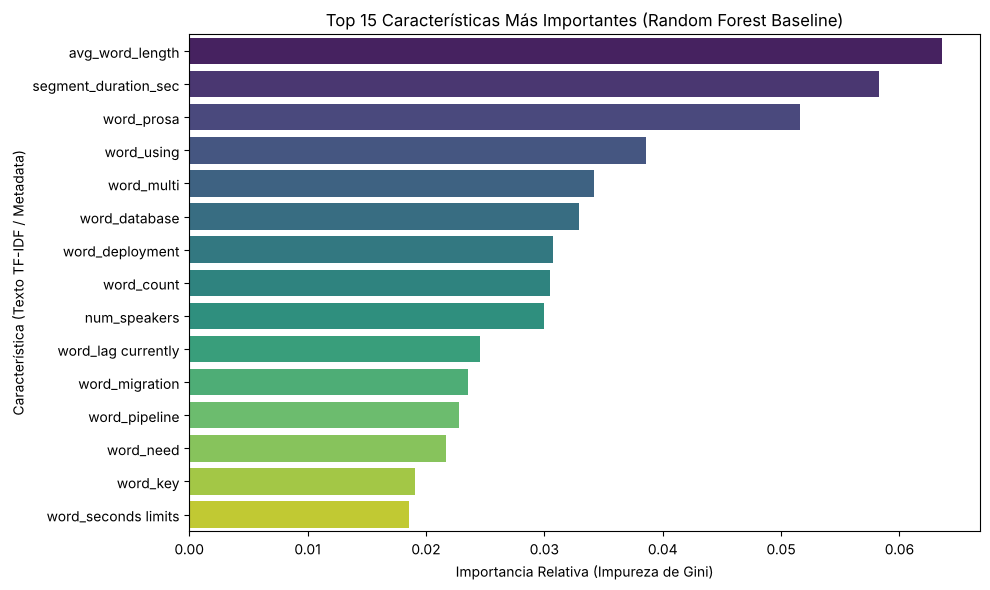

In [3]:
# 3. IMPORTANCIA DE CARACTERÍSTICAS
importances = rf_baseline.feature_importances_
indices = np.argsort(importances)[::-1]

# Tomamos el Top 15 de características
top_n = 15
top_indices = indices[:top_n]
top_features = [feature_names[i] for i in top_indices]
top_importances = importances[top_indices]

plt.figure(figsize=(10, 6))
sns.barplot(x=top_importances, y=top_features, hue=top_features, palette='viridis', legend=False)
plt.title('Top 15 Características Más Importantes (Random Forest Baseline)')
plt.xlabel('Importancia Relativa (Impureza de Gini)')
plt.ylabel('Característica (Texto TF-IDF / Metadata)')
plt.tight_layout()
plt.show()

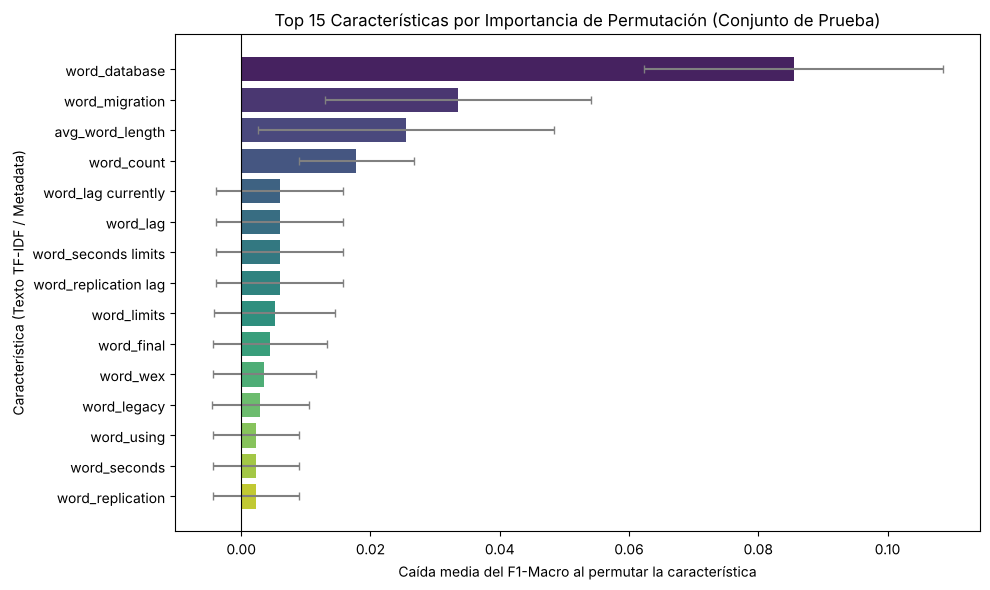

Comparación de las variables numéricas (metadata):
             feature   gini  perm_mean  perm_std
     avg_word_length 0.0636     0.0254    0.0229
          word_count 0.0305     0.0178    0.0089
segment_duration_sec 0.0583     0.0000    0.0000
        num_speakers 0.0300     0.0000    0.0000


In [4]:
# 3.1 IMPORTANCIA POR PERMUTACIÓN (complemento sin sesgo hacia variables continuas)
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf_baseline, X_test, y_test, scoring='f1_macro', n_repeats=30, random_state=42)
perm_df = pd.DataFrame({'feature': feature_names,
                        'perm_mean': perm.importances_mean,
                        'perm_std': perm.importances_std,
                        'gini': importances}).sort_values('perm_mean', ascending=False)

top_perm = perm_df.head(top_n)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_perm, x='perm_mean', y='feature', hue='feature', palette='viridis', legend=False)
plt.errorbar(top_perm['perm_mean'], range(len(top_perm)), xerr=top_perm['perm_std'], fmt='none', ecolor='gray', capsize=3)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 15 Características por Importancia de Permutación (Conjunto de Prueba)')
plt.xlabel('Caída media del F1-Macro al permutar la característica')
plt.ylabel('Característica (Texto TF-IDF / Metadata)')
plt.tight_layout()
plt.show()

print("Comparación de las variables numéricas (metadata):")
print(perm_df[perm_df['feature'].isin(num_features)][['feature', 'gini', 'perm_mean', 'perm_std']].round(4).to_string(index=False))


### Interpretación de la importancia de características

* **Gini vs. permutación:** en la gráfica de Gini, las cuatro variables de metadata aparecen en posiciones altas (`avg_word_length` y `segment_duration_sec` son las dos primeras). Al permutarlas sobre el conjunto de prueba el panorama cambia: `segment_duration_sec` y `num_speakers` tienen importancia **0.0**, es decir, el modelo no las usa para acertar. Su lugar en Gini se explica por el sesgo del método hacia variables continuas, no por capacidad predictiva.
* **La señal principal está en el contenido léxico:** la característica más importante por permutación es `word_database` (≈0.085), seguida de `word_migration` (≈0.034), ambas ligadas a la categoría `database_migration`. `avg_word_length` (≈0.025) y `word_count` (≈0.018) tienen un aporte pequeño y con alta variabilidad; además, no son señales temporales ni de audio, sino propiedades derivadas del propio texto.
* **Cautela:** la permutación se calcula sobre 12 segmentos de prueba, así que las magnitudes son orientativas; lo robusto es el contraste entre ambos métodos.
* **Implicaciones para el proyecto:** la metadata temporal y estructural (duración del segmento, número de participantes) no aporta valor para clasificar el tipo de segmento, por lo que no se justifica como insumo de clasificación; incluir características irrelevantes solo añade complejidad. El modelo distingue las categorías por *lo que se dice*, lo que refuerza que la etapa siguiente debe centrarse en la comprensión semántica de la transcripción, la fortaleza de un modelo fundacional como Gemini. Los metadatos temporales siguen siendo útiles para otros fines (ubicar y citar el momento del video en el TDD), pero no como predictores.

## 3.3 Diagnóstico de Sub/Sobreajuste (Overfitting)

Para diagnosticar el ajuste del modelo se comparan tres evidencias complementarias:

1. **F1-Macro en entrenamiento vs. prueba** (partición `GroupShuffleSplit` por sesión).
2. **Validación cruzada agrupada** (`GroupKFold`, 5 particiones por `session_id`), más estable que una sola partición de 12 segmentos.
3. **Curvas de aprendizaje** con la misma validación agrupada, para que segmentos de una misma sesión nunca queden a la vez en entrenamiento y validación.

**Diagnóstico: sobreajuste (overfitting), no subajuste.**

| Evidencia | Entrenamiento | Prueba / Validación |
|---|---|---|
| Partición train/test | ≈0.98 | ≈0.45 |
| Validación cruzada agrupada | ≈0.98 ± 0.01 | ≈0.46 ± 0.07 |
| Curva de aprendizaje (60 instancias) | ≈0.99 | ≈0.49 |

- **Signos de sobreajuste:** el F1 de entrenamiento es prácticamente perfecto en todos los tamaños de muestra, mientras que el de validación queda unos 50 puntos por debajo. El modelo memoriza los segmentos de entrenamiento en lugar de aprender reglas generales.
- **No hay subajuste:** el modelo sí aprende patrones útiles, ya que la validación supera con claridad al clasificador aleatorio (≈0.12).
- **Lectura de la curva:** la validación sigue subiendo (de ≈0.15 a ≈0.49) sin estabilizarse, por lo que **más datos etiquetados mejorarían el modelo**. La brecha se explica por el tamaño del corpus: 76 segmentos únicos frente a 104 características.

**Conclusión técnica:** con el volumen de datos disponible, el modelo clásico no generaliza lo suficiente. Para mejorarlo sería necesario recolectar y etiquetar manualmente muchas más sesiones, lo cual es costoso. Esto respalda el planteamiento del Avance 0: aprovechar un **Modelo Fundacional preentrenado (Gemini)**, que ya trae comprensión del lenguaje y puede clasificar en esquemas *Zero-Shot/Few-Shot* sin requerir un corpus etiquetado grande.

**Limitación de los datos:** las transcripciones de esta muestra piloto son simuladas a partir de plantillas. Por eso los resultados validan el flujo metodológico y la existencia de señal en el texto, pero no representan el desempeño esperado con reuniones reales, cuyo lenguaje es más variado y ruidoso. Como trabajo futuro se propone validar con transcripciones reales anonimizadas y, si se amplía el corpus sintético, generarlo con mayor diversidad (por ejemplo, paráfrasis con LLM) y aplicarlo solo al conjunto de entrenamiento. También se recomienda ajustar el vectorizador TF-IDF dentro de un `Pipeline` en cada partición para evitar compartir vocabulario entre entrenamiento y prueba.

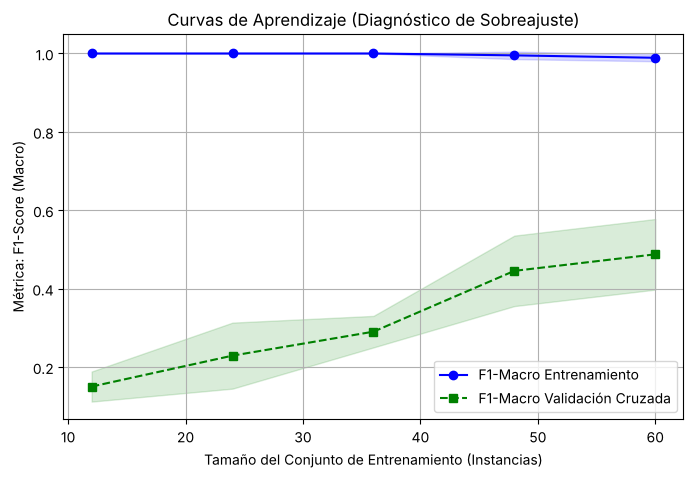

In [5]:
# 4. CURVAS DE APRENDIZAJE PARA DIAGNÓSTICO DE SOBREAJUSTE
# Se usa GroupKFold con session_id: ningún segmento de una misma sesión queda a la vez en train y validación.
train_sizes, train_scores, test_scores = learning_curve(
    estimator=rf_baseline,
    X=X, y=y, groups=groups,  # agrupación por sesión para evitar fuga entre train y validación
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=GroupKFold(n_splits=5),
    scoring='f1_macro',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, color='blue', marker='o', label='F1-Macro Entrenamiento')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, test_mean, color='green', marker='s', linestyle='--', label='F1-Macro Validación Cruzada')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='green')

plt.title('Curvas de Aprendizaje (Diagnóstico de Sobreajuste)')
plt.xlabel('Tamaño del Conjunto de Entrenamiento (Instancias)')
plt.ylabel('Métrica: F1-Score (Macro)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## 3.5 Desempeño y Expectativas

**¿Existe un desempeño histórico?** No. Hoy la clasificación de lo discutido en las sesiones y la redacción del TDD se hacen manualmente, sin un sistema automático previo ni una métrica registrada. Por eso el punto de referencia se construye en este avance.

**Niveles de referencia definidos** (F1-Macro con validación cruzada agrupada por sesión):

| Nivel | Valor | Origen |
|---|---|---|
| Azar (piso) | ≈0.12 | `DummyClassifier` estratificado |
| **Desempeño mínimo aceptable (meta de negocio)** | **≥ 0.70** | Definido por el equipo |
| Baseline Random Forest | ≈0.46 ± 0.07 | Este avance |

La meta de **F1-Macro ≥ 0.70** se fija porque, por debajo de ese nivel, al menos 3 de cada 10 segmentos quedarían en una sección incorrecta del TDD o se perderían, y la corrección manual del consultor tomaría casi tanto tiempo como redactar el documento desde cero.

**Verificación del baseline:**
- **Supera el azar:** 0.46 frente a 0.12, casi 4 veces más. Los datos sí contienen señal para resolver el problema, por lo que es viable.
- **No alcanza el nivel aceptable:** 0.46 está claramente por debajo de 0.70. El baseline no sirve como solución final, aunque sí como **referencia mínima** que cualquier modelo posterior debe superar.

**Expectativa para la siguiente etapa:** el clasificador basado en Gemini (*Zero-Shot/Few-Shot*) deberá evaluarse con la **misma métrica y la misma partición agrupada** para que la comparación sea justa, y deberá alcanzar F1-Macro ≥ 0.70. De forma complementaria, para la etapa de generación del TDD se mantiene la meta de *Faithfulness Score* > 90% (métricas de LLMOps), que mide la fidelidad factual del texto generado; es un objetivo distinto y posterior al de clasificación.

## 3.6 Alternativas evaluadas para mejorar el desempeño

Antes de cerrar el baseline se probaron dos tipos de mejora, siempre con la **misma validación cruzada agrupada por sesión** (`GroupKFold`, 5 particiones) y con el vectorizador TF-IDF ajustado **dentro de cada partición** (`Pipeline`), para que la comparación sea justa y sin fuga de información:

1. **Otros algoritmos** habituales para clasificación de texto.
2. **Más datos de entrenamiento** a partir de los duplicados eliminados y del sobremuestreo de clases minoritarias, agregados **solo al entrenamiento** de cada partición. Como control se incluye la versión incorrecta: reincorporar los duplicados *antes* de dividir los datos.

In [6]:
# 5. COMPARACIÓN DE ALTERNATIVAS (validación cruzada agrupada, sin fuga)
import warnings
from sklearn.pipeline import make_pipeline, make_union
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import cross_validate

warnings.filterwarnings('ignore')
texts = df_baseline['text_clean']
tfidf_base = lambda: TfidfVectorizer(max_features=100, ngram_range=(1, 2), stop_words='english', max_df=0.85)
tfidf_full = lambda: TfidfVectorizer(ngram_range=(1, 2), stop_words='english', sublinear_tf=True)

# 5.1 Otros algoritmos
modelos = {
    'Random Forest (baseline, solo texto)': make_pipeline(tfidf_base(), RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced')),
    'Regresión Logística': make_pipeline(tfidf_full(), LogisticRegression(max_iter=3000, class_weight='balanced')),
    'Complement Naive Bayes': make_pipeline(tfidf_full(), ComplementNB()),
    'SVM lineal (LinearSVC)': make_pipeline(tfidf_full(), LinearSVC(class_weight='balanced')),
    'SVM lineal (palabras + caracteres)': make_pipeline(
        make_union(tfidf_full(), TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), sublinear_tf=True)),
        LinearSVC(class_weight='balanced')),
}
filas = []
for nombre, modelo in modelos.items():
    r = cross_validate(modelo, texts, y, groups=groups, cv=gkf, scoring=['f1_macro', 'accuracy'], return_train_score=True)
    filas.append({'Modelo': nombre,
                  'F1-Macro Train': r['train_f1_macro'].mean(),
                  'F1-Macro CV': r['test_f1_macro'].mean(),
                  'Desv. CV': r['test_f1_macro'].std(),
                  'Accuracy CV': r['test_accuracy'].mean()})
print('--- 5.1 Comparación de algoritmos ---')
print(pd.DataFrame(filas).round(2).to_string(index=False), '\n')

# 5.2 Más datos de entrenamiento: duplicados y sobremuestreo (solo en entrenamiento)
df_con_dups = df_merged[~df_merged['text_clean'].fillna('').str.startswith('Discusión técnica sobre el segmento')].copy()
df_con_dups['text_clean'] = df_con_dups['text_clean'].fillna('')
duplicados = df_con_dups[df_con_dups.duplicated(subset='text_clean', keep='first')]

def evaluar(modo):
    scores = []
    for tr, te in gkf.split(df_baseline, y, groups):
        TR, TE = df_baseline.iloc[tr], df_baseline.iloc[te]
        peso = 'balanced'
        if modo == 'duplicados':
            extra = duplicados[duplicados['text_clean'].isin(TR['text_clean']) & ~duplicados['text_clean'].isin(TE['text_clean'])]
            TR = pd.concat([TR, extra])
        elif modo == 'sobremuestreo':
            n_max = TR['expected_category'].value_counts().max()
            TR = pd.concat([g.sample(n_max, replace=True, random_state=42) for _, g in TR.groupby('expected_category')])
            peso = None
        modelo = make_pipeline(tfidf_base(), RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight=peso))
        modelo.fit(TR['text_clean'], TR['expected_category'])
        scores.append(f1_score(TE['expected_category'], modelo.predict(TE['text_clean']), average='macro', zero_division=0))
    return np.mean(scores), np.std(scores)

filas = []
for modo, etiqueta in [('base', 'Sin duplicados (baseline)'),
                       ('duplicados', 'Duplicados solo en entrenamiento'),
                       ('sobremuestreo', 'Sobremuestreo de clases minoritarias en entrenamiento')]:
    m, sd = evaluar(modo)
    filas.append({'Estrategia': etiqueta, 'F1-Macro CV': m, 'Desv. CV': sd})

# Control: duplicados reincorporados ANTES de dividir (fuga de información)
r_fuga = cross_validate(make_pipeline(tfidf_base(), RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced')),
                        df_con_dups['text_clean'], df_con_dups['expected_category'], groups=df_con_dups['session_id'],
                        cv=gkf, scoring='f1_macro')
filas.append({'Estrategia': 'CONTROL: duplicados antes de dividir (fuga)', 'F1-Macro CV': r_fuga['test_score'].mean(), 'Desv. CV': r_fuga['test_score'].std()})
print('--- 5.2 Más datos de entrenamiento ---')
print(pd.DataFrame(filas).round(2).to_string(index=False))


--- 5.1 Comparación de algoritmos ---
                              Modelo  F1-Macro Train  F1-Macro CV  Desv. CV  Accuracy CV
Random Forest (baseline, solo texto)            0.94         0.46      0.16         0.54
                 Regresión Logística            1.00         0.52      0.10         0.74
              Complement Naive Bayes            1.00         0.51      0.03         0.74
              SVM lineal (LinearSVC)            1.00         0.50      0.05         0.72
  SVM lineal (palabras + caracteres)            1.00         0.55      0.09         0.79 



--- 5.2 Más datos de entrenamiento ---
                                           Estrategia  F1-Macro CV  Desv. CV
                            Sin duplicados (baseline)         0.46      0.16
                     Duplicados solo en entrenamiento         0.42      0.06
Sobremuestreo de clases minoritarias en entrenamiento         0.28      0.04
          CONTROL: duplicados antes de dividir (fuga)         0.59      0.14


### Conclusiones de las alternativas evaluadas

* **Otros algoritmos:** los modelos lineales (Regresión Logística, Naive Bayes, SVM) obtienen un F1-Macro algo mayor que Random Forest, lo esperado en clasificación de texto con pocos datos. Sin embargo, la diferencia es del mismo orden que la desviación estándar entre particiones, así que con 76 segmentos no se puede afirmar que uno sea claramente superior. Todos llegan a F1 ≈ 1.0 en entrenamiento: el sobreajuste es común a todos los algoritmos.
* **Más datos de entrenamiento:** reincorporar los duplicados o sobremuestrear las clases minoritarias **solo en entrenamiento** no mejora el desempeño, porque repetir la misma frase no aporta información nueva y el desbalance ya se compensa con `class_weight='balanced'`.
* **Control de fuga:** la única estrategia que sube la métrica es reincorporar los duplicados *antes* de dividir los datos, porque la misma frase queda en entrenamiento y en prueba y el modelo acierta por memoria, no por aprendizaje. Esa cifra no es válida y se descarta; confirma que eliminar los duplicados era necesario.
* **Conclusión:** ninguna alternativa clásica se acerca a la meta de F1-Macro ≥ 0.70. El límite no está en el algoritmo sino en el volumen y la diversidad de los datos etiquetados, lo que refuerza la conclusión de la sección 3.5: la siguiente etapa debe apoyarse en un modelo fundacional preentrenado (Gemini) y compararse contra estos valores con la misma metodología.